# 2020 — Neural Scaling Laws (Kaplan) and Compute-Optimal Training (Chinchilla, 2022)

**Papers:** Jared Kaplan et al., *"Scaling Laws for Neural Language Models"* (2020); Jordan Hoffmann et al., *"Training Compute-Optimal Large Language Models"* (Chinchilla, 2022). Earlier: Hestness et al. (2017).

Test loss of language models falls as a smooth **power law** in model size $N$, data $D$ and compute $C \approx 6ND$, over many orders of magnitude:

$$L(N, D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}}$$

$E$ is the irreducible loss, the entropy of the data itself. Two consequences shaped the field:
- **Predictability:** train small models, fit the curve, and forecast a big model's loss before spending the money.
- **Compute-optimal allocation:** for a fixed budget, Chinchilla found you should grow parameters and tokens **equally** ($N_{opt} \propto C^{0.5}$, roughly 20 tokens per parameter). GPT-3-era models were heavily under-trained. (Since 2023 models are often trained far *past* this point, because a smaller model is cheaper to serve.)

**Our lab:** text from a random **Markov chain** over 64 tokens. Its true entropy is known exactly, so we know $E$ in advance. We train tiny Transformers across sizes and token budgets and fit the laws ourselves. Here a model's width limits how well it can represent the 64×64 transition table, which plays the role that world knowledge plays for real LLMs.

![Diagram: Scaling laws (Kaplan et al., 2020; Hoffmann et al., 2022)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/45_2020_scaling_laws.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
V, CTX = 64, 32
g = torch.Generator().manual_seed(0)
probs = torch.distributions.Dirichlet(torch.full((V,), 0.05)).sample((V,))        # P(next | current), peaky rows
stationary = torch.ones(V) / V
for _ in range(500): stationary = stationary @ probs
H_rows = -(probs * probs.clamp_min(1e-12).log()).sum(-1)
ENTROPY = (stationary * H_rows).sum().item()
print(f"irreducible loss E = entropy rate of the source = {ENTROPY:.4f} nats/token (uniform guessing = {math.log(V):.2f})")
probs_dev = probs.to(device)

def sample_batch(B):
    """Fresh samples every time: infinite data, so no overfitting and D = tokens seen."""
    x = torch.empty(B, CTX + 1, dtype=torch.long, device=device)
    x[:, 0] = torch.randint(0, V, (B,), device=device)
    for t in range(1, CTX + 1):
        x[:, t] = torch.multinomial(probs_dev[x[:, t - 1]], 1).squeeze(1)
    return x[:, :-1], x[:, 1:]

irreducible loss E = entropy rate of the source = 1.7990 nats/token (uniform guessing = 4.16)


In [3]:
class TinyGPT(nn.Module):
    def __init__(self, d, n_layers=2, heads=2):
        super().__init__()
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(CTX, d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True, norm_first=True, activation="gelu")
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.head = nn.Linear(d, V)
        self.register_buffer("mask", torch.triu(torch.full((CTX, CTX), float("-inf")), 1))
    def forward(self, x):
        return self.head(self.blocks(self.tok(x) + self.pos.weight, mask=self.mask, is_causal=True))
    def n_params(self):                                       # all parameters (embeddings matter at this tiny scale)
        return sum(p.numel() for p in self.parameters())

EVAL = [sample_batch(256) for _ in range(4)]
def train(d, steps, B=32, lr=3e-3):
    seed_everything(0); m = TinyGPT(d).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.05)
    for _ in range(steps):
        x, y = sample_batch(B); loss = F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    m.eval()
    with torch.no_grad(): val = np.mean([F.cross_entropy(m(x).reshape(-1, V), y.reshape(-1)).item() for x, y in EVAL])
    return m.n_params(), steps * B * CTX, val

## 1. Loss vs. model size (fixed, generous data)

In [4]:
t0 = time.time()
widths = [2, 4, 8, 16, 32]
size_runs = [train(d, 1500) for d in widths]
for (N, D, L), d in zip(size_runs, widths): print(f"d={d:3d}  N={N:7,d}  loss {L:.4f}  excess {L - ENTROPY:.4f}")
print(f"({time.time() - t0:.0f}s)")

from scipy.optimize import curve_fit
Ns = np.array([r[0] for r in size_runs], float); Ls = np.array([r[2] for r in size_runs])
power = lambda N, A, alpha: ENTROPY + A * N ** (-alpha)
(A_fit, alpha_fit), _ = curve_fit(power, Ns, Ls, p0=(10, 0.5), maxfev=20000)
print(f"fit: L(N) = {ENTROPY:.3f} + {A_fit:.2f} * N^(-{alpha_fit:.3f})")

d=  2  N=    532  loss 3.7050  excess 1.9060
d=  4  N=  1,192  loss 2.8475  excess 1.0485
d=  8  N=  3,088  loss 2.2184  excess 0.4194
d= 16  N=  9,184  loss 1.9204  excess 0.1214
d= 32  N= 30,592  loss 1.8339  excess 0.0349
(40s)


fit: L(N) = 1.799 + 371.45 * N^(-0.838)


## 2. Loss vs. data (fixed model)

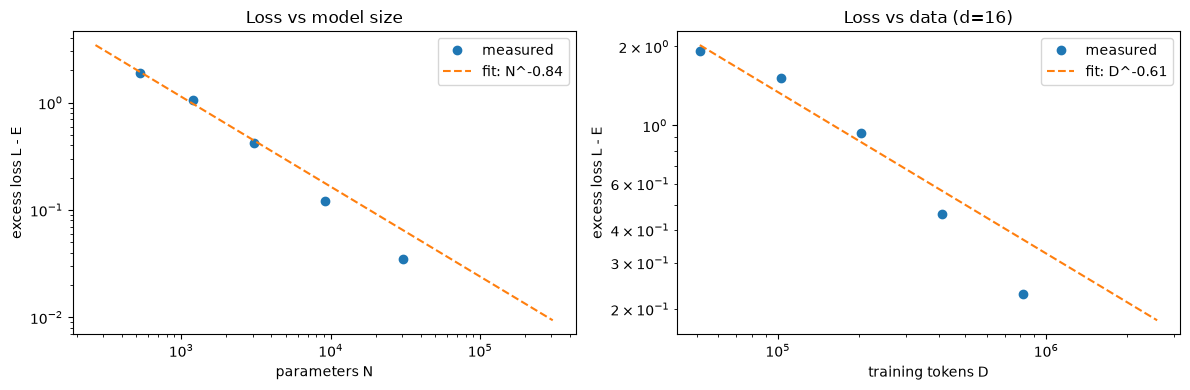

In [5]:
data_runs = [train(16, s) for s in [50, 100, 200, 400, 800]]
Ds = np.array([r[1] for r in data_runs], float); LDs = np.array([r[2] for r in data_runs])
(B_fit, beta_fit), _ = curve_fit(lambda D, B, beta: ENTROPY + B * D ** (-beta), Ds, LDs, p0=(10, 0.3), maxfev=20000)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
nn_ = np.logspace(np.log10(Ns.min()) - 0.3, np.log10(Ns.max()) + 1, 100)
axes[0].loglog(Ns, Ls - ENTROPY, "o", label="measured"); axes[0].loglog(nn_, A_fit * nn_ ** (-alpha_fit), "--", label=f"fit: N^-{alpha_fit:.2f}")
axes[0].set(xlabel="parameters N", ylabel="excess loss L - E", title="Loss vs model size"); axes[0].legend()
dd = np.logspace(np.log10(Ds.min()), np.log10(Ds.max()) + 0.5, 100)
axes[1].loglog(Ds, LDs - ENTROPY, "o", label="measured"); axes[1].loglog(dd, B_fit * dd ** (-beta_fit), "--", label=f"fit: D^-{beta_fit:.2f}")
axes[1].set(xlabel="training tokens D", ylabel="excess loss L - E", title="Loss vs data (d=16)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. IsoFLOP curves: the Chinchilla experiment
For each compute budget $C = 6ND$, train models of several sizes, each getting exactly the tokens the budget allows. The best size for each budget traces out $N_{opt}(C)$.

C=1.0e+10: best N=3,088 trained on D=539,648 tokens (D/N = 174.8), loss 2.6894


C=4.0e+10: best N=9,184 trained on D=724,992 tokens (D/N = 78.9), loss 2.0552


C=1.6e+11: best N=30,592 trained on D=871,424 tokens (D/N = 28.5), loss 1.8639


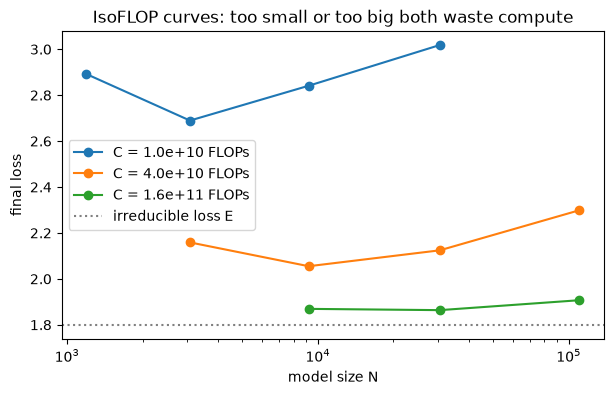

In [6]:
budgets = [1e10, 4e10, 1.6e11]
iso = {}
for C in budgets:
    iso[C] = []
    for d in [2, 4, 8, 16, 32, 64]:
        N = TinyGPT(d).n_params(); steps = int(C / (6 * N * 32 * CTX))
        if steps < 50 or steps > 3000: continue          # skip runs too short to mean anything or too slow for a notebook
        iso[C].append(train(d, steps))
    best = min(iso[C], key=lambda r: r[2])
    print(f"C={C:.1e}: best N={best[0]:,} trained on D={best[1]:,} tokens (D/N = {best[1] / best[0]:.1f}), loss {best[2]:.4f}")
plt.figure(figsize=(7, 4))
for C, runs in iso.items():
    plt.semilogx([r[0] for r in runs], [r[2] for r in runs], "o-", label=f"C = {C:.1e} FLOPs")
plt.axhline(ENTROPY, ls=":", c="gray", label="irreducible loss E")
plt.xlabel("model size N"); plt.ylabel("final loss"); plt.legend(); plt.title("IsoFLOP curves: too small or too big both waste compute"); plt.show()

## Takeaways
- Loss falls smoothly and predictably toward the entropy floor as $N$ or $D$ grows, even at this toy scale.
- For a fixed budget there is a **best model size**. Bigger isn't automatically better: an over-sized model sees too few tokens.
- Our exponents and the tokens-per-parameter ratio come from a tiny synthetic task. Real LLM values differ (Chinchilla: about 20 tokens per parameter), but the method of fitting small runs and extrapolating is exactly how labs plan frontier training runs.